# Inicialización de libreta y lectura de BD

In [1]:
import sys
import os
sys.path.append(os.path.abspath("../src"))
from analizador_datos import AnalizadorDeDatos

In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# EDA

## Objetivo

Realizar un análisis exploratorio de datos (EDA) sobre el conjunto de datos Titanic, para comprender la estructura de información, identificar problemas en los datos, describir las principales características de los pasajeros y explorar qué variables podrían estar asociadas con la probabilidad de supervivencia.

## Carga de datos

In [3]:
df = pd.read_csv('../data/Titanic_train.csv')

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Diccionario de datos

La base de datos contiene doce columnas, descritas de la siguiente forma:

| Variable | Definition | Key |
|-----------|------------|-----|
| survival | Survival | 0 = No, 1 = Yes |
| pclass | Ticket class | 1 = 1st, 2 = 2nd, 3 = 3rd |
| sex | Sex | |
| Age | Age in years | |
| sibsp | # of siblings / spouses aboard the Titanic | |
| parch | # of parents / children aboard the Titanic | |
| ticket | Ticket number | |
| fare | Passenger fare | |
| cabin | Cabin number | |
| embarked | Port of Embarkation | C = Cherbourg, Q = Queenstown, S = Southampton |


Conceptualmente, los valores mostrados en el encabezado son congruentes con la definición en kaggle.
Age está definido como flotante, pero se puede simplificar a tipo entero

### Comprensión de datos

In [5]:
# Dimensiones
df.shape

(891, 12)

In [6]:
# Tipos de datos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


### Notas sobre comprensión de datos

La base da datos está estructurada con 12 columnas y dispone de 891 registros

El conjunto de datos contiene variables numéricas y categóricas. Las variables Age y Fare se almacenan como valores flotantes, mientras que PassengerId, Survived, Pclass, SibSp y Parch se encuentran registradas como enteros

### Calidad de datos

Se prepara analizador de datos, las funciones dentro de esta clase las desarrollé durante la materia Ciencia y Analítica de Datos 

In [7]:
analizador = AnalizadorDeDatos(df)

In [8]:
# Valores faltantes
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

### Hallazgos sobre faltantes
Las columnas Age, Cabin y Embarked presentan registros faltantes:
* Age: 177 / 891
* Cabin:  687 / 891
* Embarked 2 / 891

In [9]:
# Duplicados
analizador.eliminar_duplicados()

Duplicados encontrados: 0
Eliminando duplicados...
Reiniciando índice...
Duplicados finales: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


### Estadística descriptiva

In [10]:
### Variables numéricas
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Hallazgos sobre variables
Hallazgos:
* Edad promedio: 29.7 años
* Tarifa promedio: $32.2
* Edad máxima: 80 años
* Cantidad de hermanos / cónyuge: valores de 0 a 8, percentiles 25% y 50% indican 0. 75% indica 1 --> la mitad de los pasajeros viajaba sin hermanos o cónyuge y el 75% viajaba con máximo 1 acompañante.
* Cantidad de hijos / padres: valores de 0 a 6, percentiles 25%, 50% y 75% indican 0. --> La gran mayoría de los pasajeros no viajaba acompañada por padres o hijos. Los grupos familiares extensos eran poco frecuentes.
* Tarifa máxima: $512.33

## Reclasificación de variables para análisis

Aunque algunas variables están almacenadas como valores numéricos, su significado corresponde a categorías, para facilitar su interpretación, las variabels Survived y Pclass se tratarán como categóricas.

Survived:
* 0 = No sobrevivió
* 1 = Sobrevivió

Pclass:
* 1 = Primera Clase
* 2 = Segunda Clase
* 3 = Tercera Clase

In [11]:

df_eda = df.copy()

df_eda["Survived"] = df_eda["Survived"].map({
0: "No sobrevivió",
1: "Sobrevivió"
})

df_eda["Pclass"] = df_eda["Pclass"].map({
1: "Primera",
2: "Segunda",
3: "Tercera"
})

# Reiniciar analizador
analizador_eda = AnalizadorDeDatos(df_eda)

## Análisis univariado

## Variables categóricas

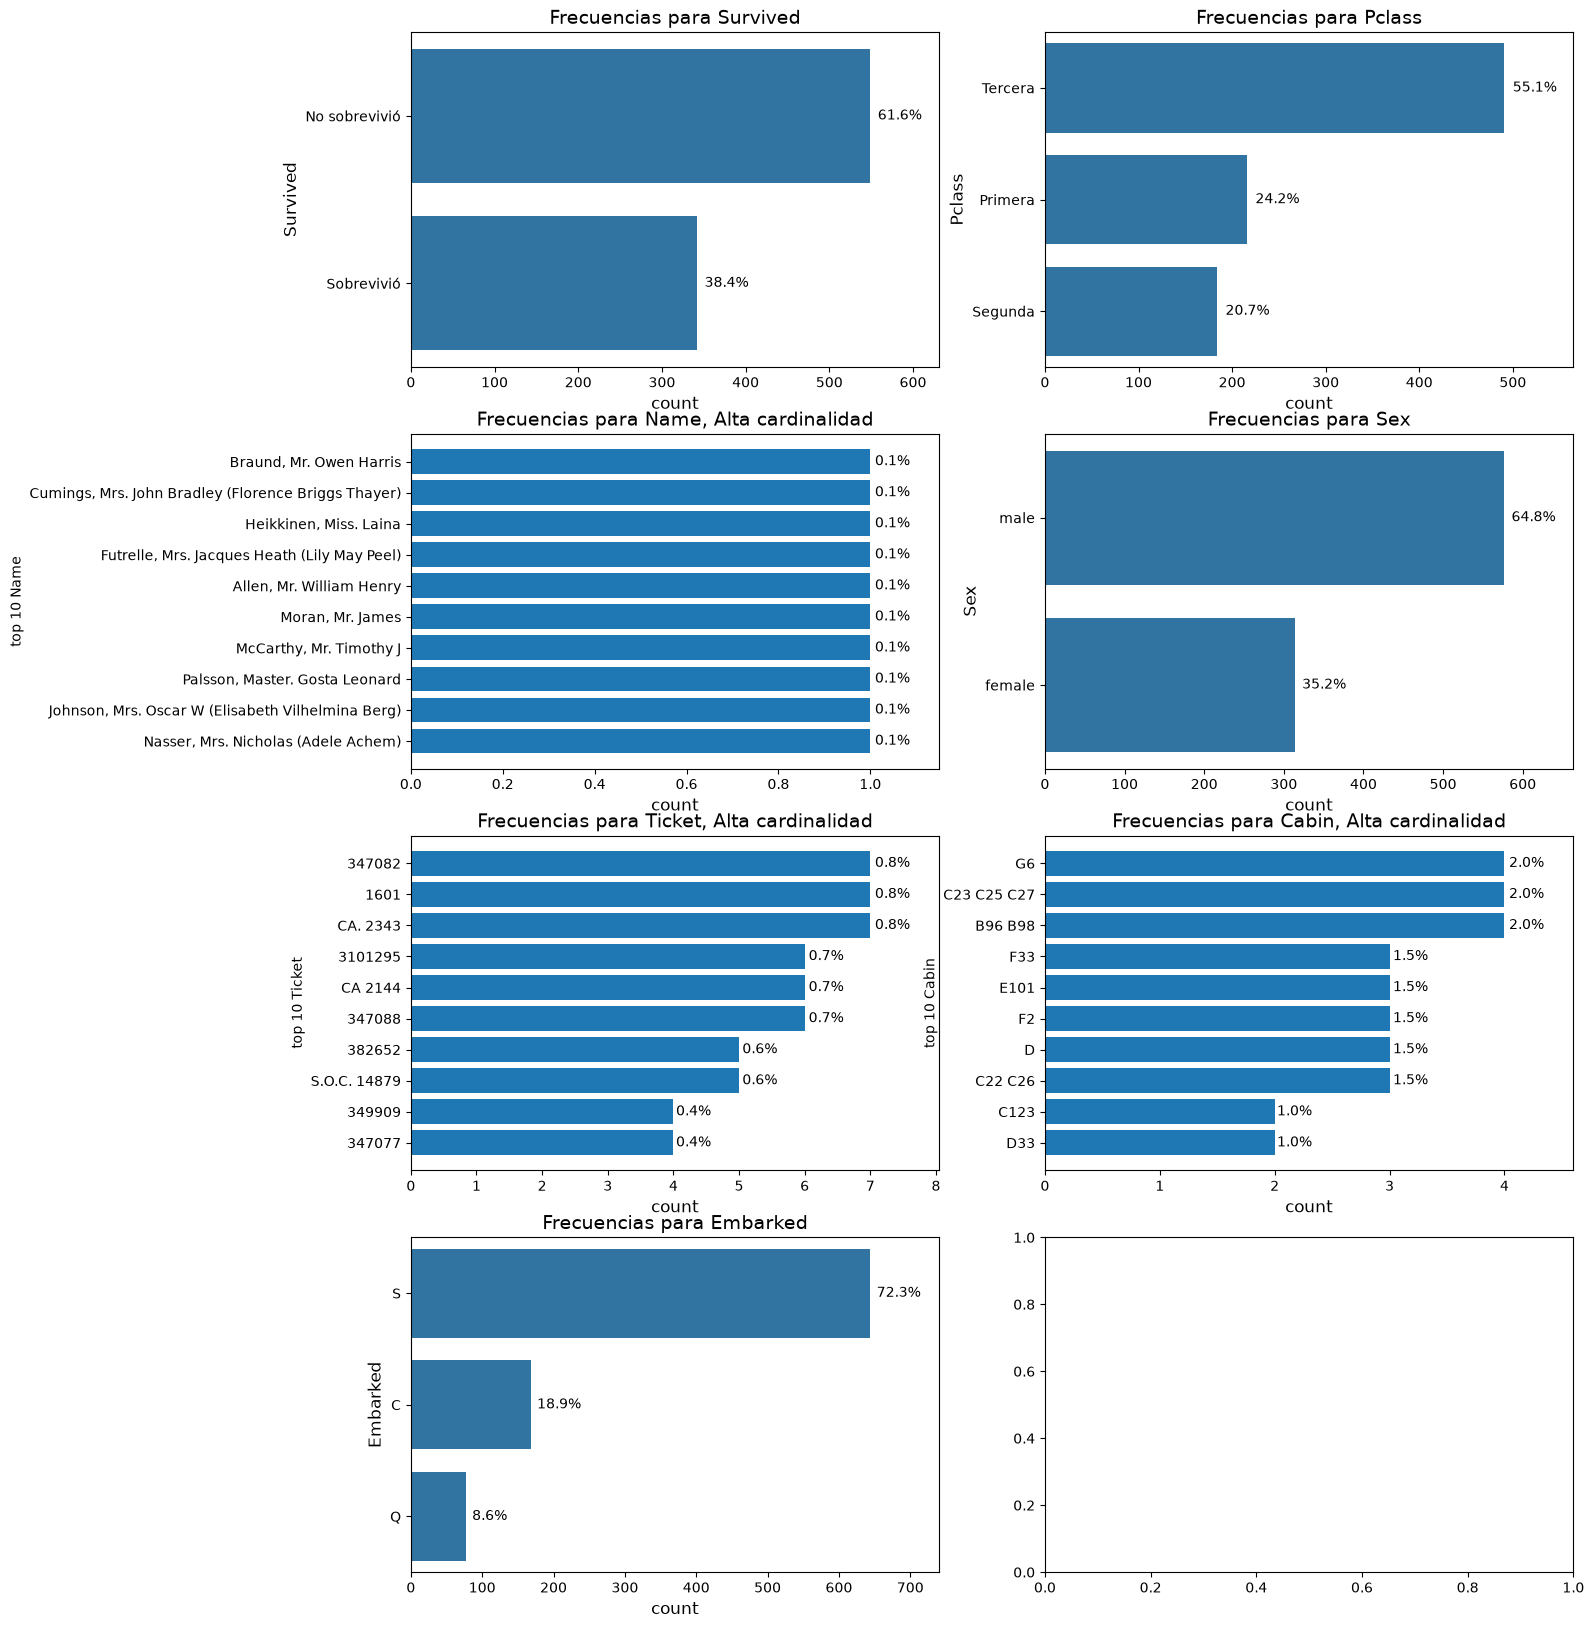

In [12]:
#Analizar la distribución de las variables categóricas
analizador_eda.graficar_frecuencias_en_categorias(rowsqty=4, colsqty=2, size_x=15, size_y=20)


### Hallazgos en variables categóricas

* Sobrevivió prácticamente una tercera parte de los pasajeros (38.4%)
* La tercera clase representaba más de la mitad de los pasajeros (55.1%)
* Predominan los pasajeros hombres (64.8% de hombres vs 35.2% de mujeres)
* La mayoría de los pasajeros embarcó en Southampton




### Variables numéricas

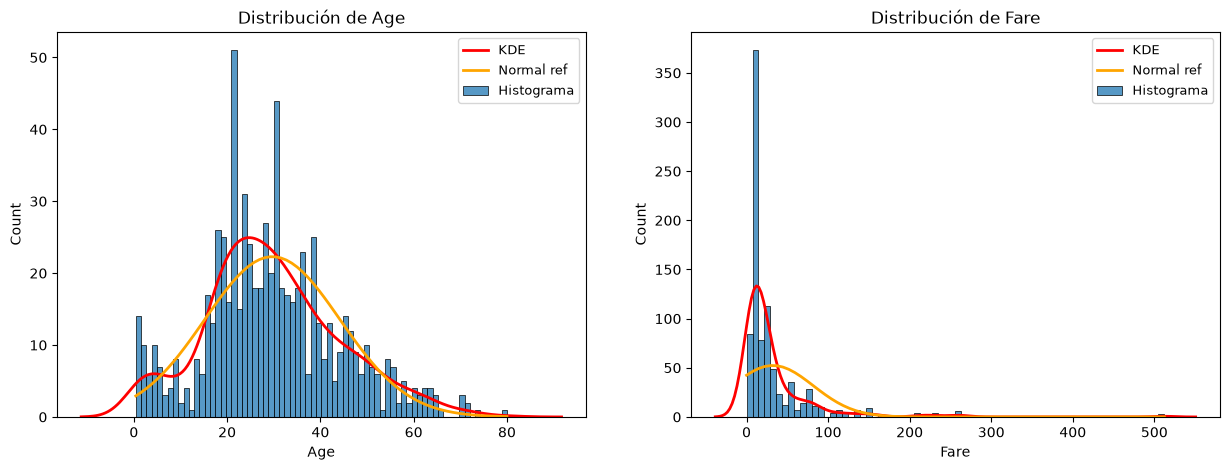

In [13]:
analizador_eda.graficar_histogramas(
    columnas=["Age", "Fare"],
    rowsqty=1, colsqty=2,
    size_x=15, size_y=5,
    height_stat="count",
    num_bins=70
)

### Hallazgos en variables numéricas

* Age: se ve una concentración en menores de 15 años y una más en el rango de los 18 a los 40 años.
* Fare:
    * La mayor concentración se localiza en tarifas bajas, menores a los 30 dólares, sin embargo el promedio ronda los 32 dólares debido a qe un grupo de pasajeros pagó boletos considerablemente más caros.
    * La diferencia observada sugiere una importante desigualdad en el costo de los boletos, asociada a las distintas clases de viaje.


## Análisis bivariado

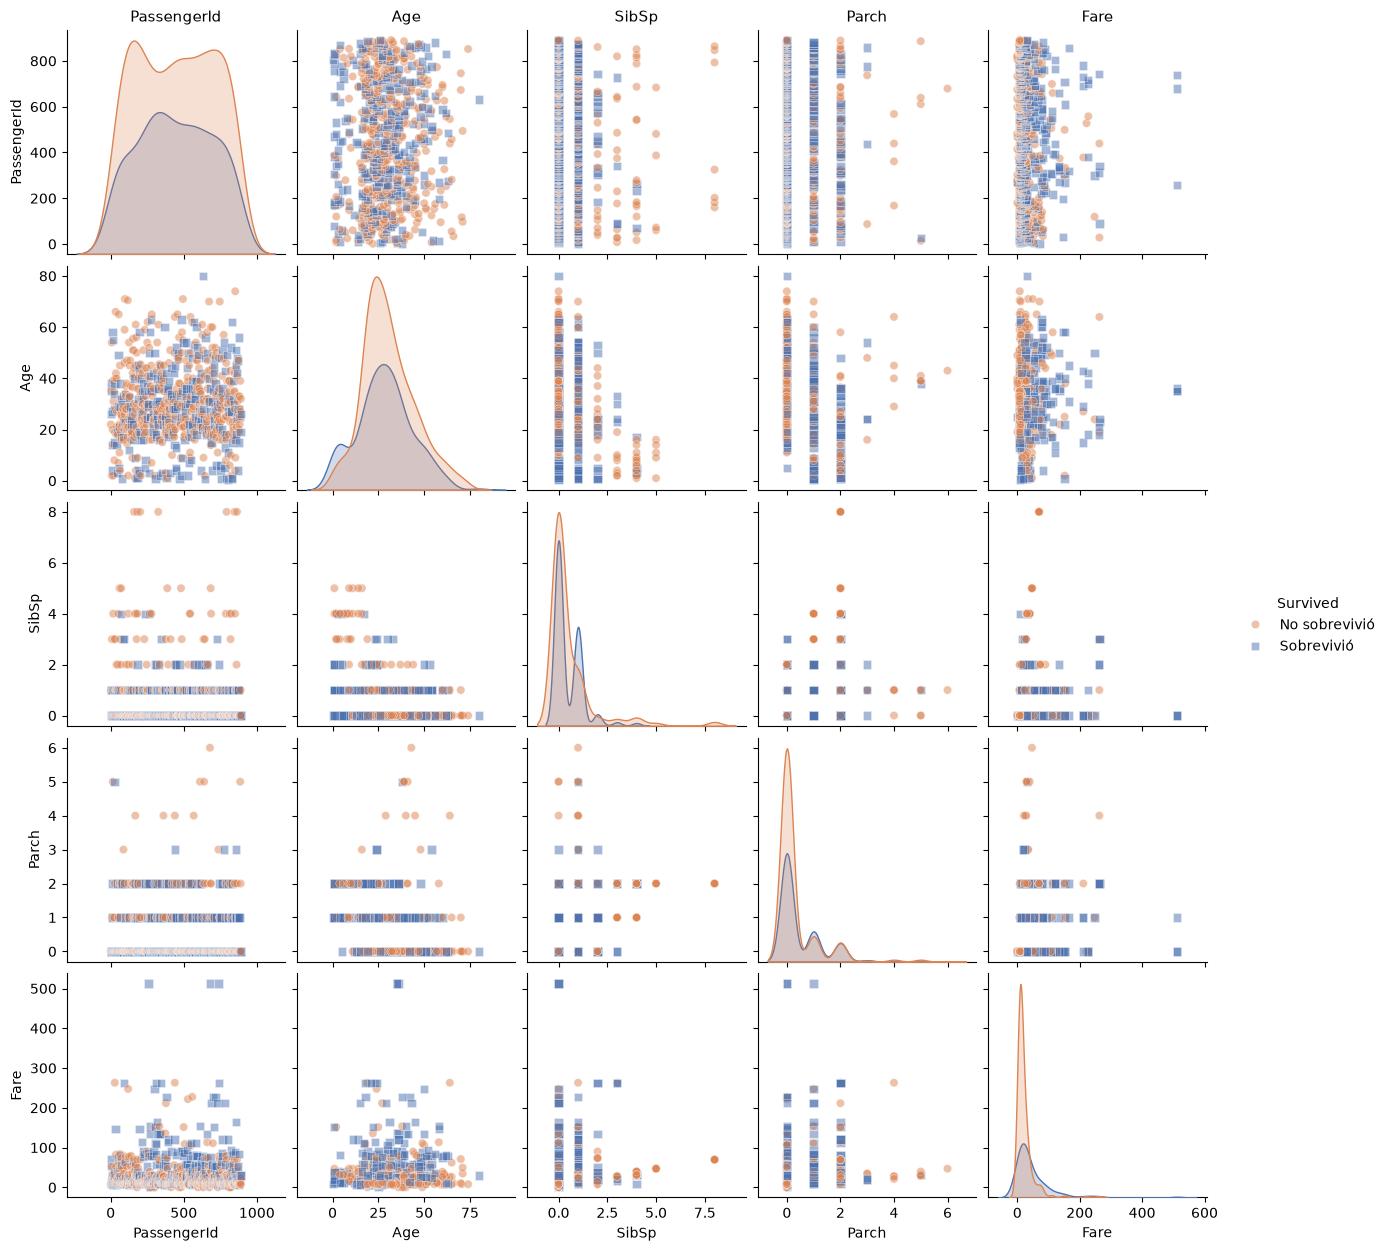

In [14]:
grafico = sns.pairplot(df_eda, hue='Survived', palette=sns.color_palette("deep")[:2][::-1],diag_kind='kde', markers=["o", "s"], plot_kws={'alpha': 0.5})
# Agregar títulos arriba de cada columna
for ax, col in zip(grafico.axes[0], grafico.x_vars):
    ax.set_title(col, fontsize=11)

## Hallazgos de análsis bivariado

- Diagonal: las gráficas de la diagonal permiten analizar la distribución individual de cada variable para los grupos de pasajeros sobrevivientes y no sobrevivientes.
    * Age: Ambas distribuciones presentan una forma similar y un amplio grado de superposición, aunque no se observa una separación clara entre ambos grupos, se aprecia una mayor proporción de sobrevivientes en las edades más tempranas. Esto sugiere quelos pasajeros de menor edad pudieron tener más probabilidades de supervivencia.
    * SibSp: La distribución se concentra en los valores de 0 y 1. Aunque se observa una fuerte superposición entre ambos grupos, los pasajeros que viajaban con un único hermano o cónyuge parecen presentar una mayor proporción de supervivencia que aquellos que viajaban solos.
    * Fare: Aunque existe una superposición entre sobrevivientes y no sobrevivientes, los sobrevivientes se concentran en las tarifas más elevadas, lo que sugiere una posible relación positiva entre el precio del boleto pagado y la probabilidad de supervivencia.
- Bivariados:
    * Existe una relación inversa entre Fare y Pclass, como era de esperarse.
    * No se observan relaciones lineales fuertes para Age, SibSp y Parch.


### Análisis específico de supervivencia

<Axes: xlabel='Sex', ylabel='count'>

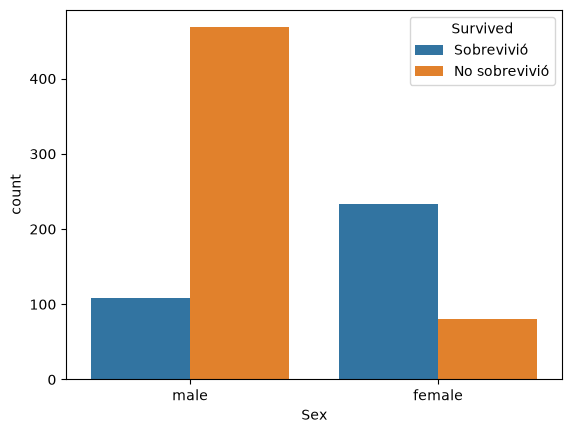

In [15]:
# Sobrevivencia por sexo

sns.countplot(data=df_eda, x="Sex", hue="Survived", hue_order=["Sobrevivió", "No sobrevivió"])

<Axes: xlabel='Pclass', ylabel='count'>

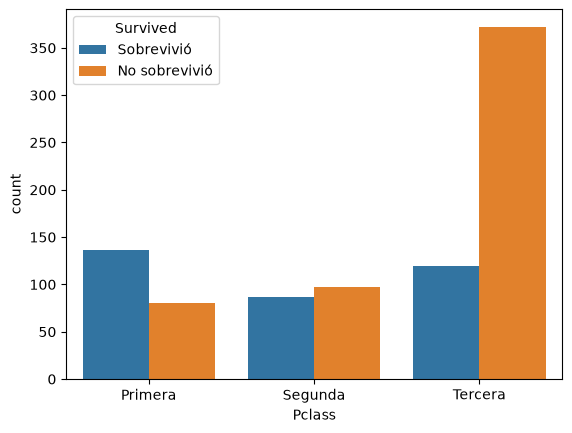

In [16]:
# Sobrevivencia por clase
sns.countplot( df_eda, x="Pclass", hue="Survived", order=["Primera", "Segunda", "Tercera"], hue_order=["Sobrevivió", "No sobrevivió"])

<Axes: xlabel='Survived', ylabel='Fare'>

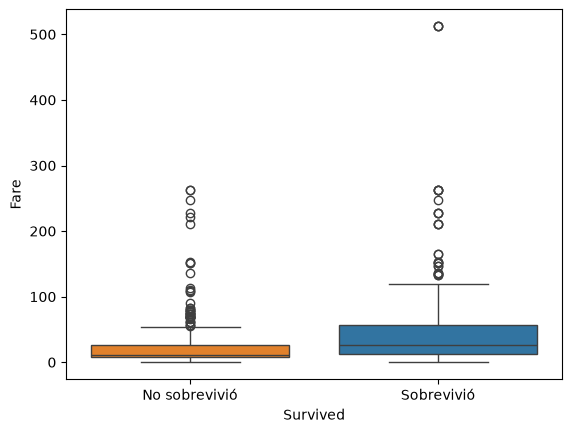

In [17]:
# Sobrevivencia por tarifa
sns.boxplot(df_eda, x="Survived", y="Fare", hue="Survived", hue_order=["Sobrevivió", "No sobrevivió"])

## Hallazgos sobre análisis específico de supervivencia
* Sexo: La proporción de supervivientes es considerablemente mayor entre las mujeres, en contraste con los hombres, donde la proporción es inversa. Esto sugiere que el sexo del pasajero estuvo asociado con las probabilidades de supervivencia.
* Clase: La proporción de supervivientes es mayor en la primera clase, mientras que la tercera clase concentra la mayor proporción de no supervivientes. La segunda clase muestra un comportamiento intermedio, lo que sugiere una relación entre la clase del boleto y la supervivencia.
* Tarifa (Caja y Bigote): La mediana y el rango de Fare son mayores para los pasajeros que sobrevivieron, además los sobrevivientes se dispersan hacia tarifas elevadas. Esto sugiere que los pasajeros que pagaron boletos más costosos tendieron a presentar mayores tasas de supervivencia.

## Conclusiones de análisis EDA

* La base de datos contiene 891 registros y 12 variables, con información demográfica, económica y familiar de los pasajeros del Titanic. Se identificaron valores faltantes en las variables `Age`, `Cabin` y `Embarked`, así que será necesariotratar estos datos.
* La población de pasajeros se concentra principalmente en personas de entre los 18 y 40 años. Asimismo, la distribución de edades muestra una presencia importante de menores de edad dentro del conjunto de datos. 
* La tarifa pagada presenta una distribución desigual. La mayoría de los pasajeros adquirió boletos de bajo costo, mientras que un grupo reducido pagó tarifas considerablemente más elevadas. Este comportamiento es consistente con la existencia de distintas clases de viaje a bordo.
* La tercera clase concentraba más de la mitad de los pasajeros, predominaban los hombres y el puerto de Southampton representaba el principal punto de embarque. Asimismo, aproximadamente el 38% de los pasajeros sobrevivió al accidente.
* El análisis bivariado muestra una amplia superposición entre pasajeros sobrevivientes y no sobrevivientes. Sin embargo, se observan algunos patrones relevantes:
    * Los pasajeros de menor edad presentan una mayor proporción de supervivencia
    * Los sobrevivientes muestran una mayor presencia en los rangos de tarifa más elevados
    
    Estas observaciones sugieren que la edad y el nivel de servicio asociado al boleto podrían estar relacionados con las probabilidades de supervivencia. 

**En conjunto, los resultados sugieren que `Age`, `Fare`, `Sex` y `Pclass` contienen información potencialmente relevante para explicar la supervivencia de los pasajeros y podrían constituir variables de interés para la construcción de modelos predictivos**

# Limpieza de datos

Durante la exploración de datos se encontraron valores faltantes en las variables `Age`, `Cabin` y `Embarked`. Se manejaran de la siguiente forma:
* Age: imputar usando la mediana para evitar que los valores extremos afecten la estimación.
* Cabin: eliminar la variable, ya que es una variable categórica con más del 75% de registros faltantes, y una imputación introduciría ruido considerable.
* Embarked: imputar usando la moda, ya que es una variable categórica y solo tiene 2 registros faltantes.


In [18]:
df_clean = df.copy()

df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])
df_clean.drop(columns=["Cabin"], inplace=True)

# Modelo baseline

Usaremos DecisionTreeClassifier como baseline por su simplicidad, facilidad de interpretación y cpacidad para clasificar los pasajeros a través de variables como la edad, tarifa y clase del boleto.

In [19]:
X = df_clean[["Pclass", "Age", "SibSp", "Parch", "Fare"]]
y = df_clean["Survived"]

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [21]:
model = DecisionTreeClassifier(max_depth=3, random_state=1)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in 

## Evaluación

In [22]:
accuracy = model.score(X_test, y_test)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.6872


## Notas sobre evaluación
La exactitud obtenida por el modelo baseline fue de 68.72%.

Esto indica que el modelo clasifica de forma correcta aproximadamente 69 de cada 100 pasajeros. Al tratarse de un modelo base, el objetivo principal es establecer un punto de referencia que permita comparar futuros modelos más sofisticados.

# MLFlow

In [23]:
import mlflow

with mlflow.start_run():

    p_max_depth = 3
    p_random_state = 1
    model = DecisionTreeClassifier(max_depth=p_max_depth, random_state=p_random_state)
    model.fit(X_train, y_train)

    accuracy = model.score(X_test, y_test)

    mlflow.log_param("max_depth", p_max_depth)
    mlflow.log_param("random_state", p_random_state)
    mlflow.log_metric("accuracy", accuracy)

    print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.6872


# Reflexión final

**¿Qué mejoraría en este flujo aplicando prácticas de MLOps y porqué?**

La rutina actual trabaja con un archivo de base de datos fijo, sin embargo es importante asegurar la reproducibilidad y trazabilidad del experimento. Utilizaría versionado de datos para asegurar que cualquier resultado se peuda reproducir exactamente utilizando la misma versión del conjunto de datos y las mismas transformaciones aplicadas durante la limpieza.
Durante este ejercicio, el tratamiento de los valores faltantes se realizó de manualmente a partir del análisis del conjunto de datos. En un flujo de MLOps, estasreglas de limpieza podrían integrarse dentro de un pipeline automatizado para asegurar consistencia y reducir la intervención manual cada vez que se entrene el modelo.
También usaría MLflow para registrar nuevas versiones de modelos, incluyendo los parámetros usados y las métricas obtenidas, para así poder comparar diferentes iteraciones y comprender el impacto de cada cambio aplicado.

Aunque el conjunto de datos de Titanic corresponde a un evento histórico y no recibe nuevos registros (salvo que hubiera algún nuevo descubrimiento), el seguimiento de experimentos continúa siendo valioso para m,antener la trazabilidad del proceso y comparar distintos enfoques de modelado.

Dentro de mi área profesional, lo aprendido en este ejercicio refuerza la importancia de trabajar con procesos reproducibles, documentados y medibles en proyectos de Machine Learning. Con el uso de MLflow y la integración de herramientas como VSCode integrado con Ubuntu, me queda claro cómo se puede facilitar la gestión, monitoreo y mejora contínua de mis modelos en un entorno productivo.